# E235 · Why would learning A improve B?

**Complete** · E235 finished  
Updated 2026-11-23T13:26:03+01:00 Stockholm

Eight fresh raw BDD walks have distinct initial A, first B, returning A and fresh continuation-B captures. Frozen MAE features assign captures before evaluation labels are read. Each walk learns A and then B with incoming-only MAE, then starts every branch from the same post-B model and optimizer. Trainable arms use batch size two, learning rate 7.5e-5 and 192 updates, with reads at 48, 96 and 192. Four independent mask draws are paired across branches.

Continue B sees fresh frames from a distinct visually matched B capture. Replay-only uses the 64-image bank from the observed first B capture. The mixed arm uses the same bank and historical samples in corresponding slots at 25% replay. Freeze provides the exact post-B reference.

Separate raw A/B holdouts anchor the annotated validation panels. The primary four-task score uses scene, weather, traffic light and pedestrian balanced accuracy. Per-class stratification after stream selection produces disjoint A/B evaluation subsets with at least 30 examples of every task class. Lighting and scene kNN are separate diagnostics. The label-blind split uses equal halves of the keyframe pool for a sensitivity check. Walk intervals condition on the shared validation corpus. Labels never enter the learner or clip selection.

| Walk | A/B cosine distance | New B vs first B distance | Min supported class count | Min label-blind primary class count |
| --- | --- | --- | --- | --- |
| 1 | 0.640 | 0.037 | 35 | 24 |
| 2 | 0.211 | 0.017 | 35 | 27 |
| 3 | 0.795 | 0.004 | 35 | 25 |
| 4 | 0.233 | 0.013 | 35 | 24 |
| 5 | 0.094 | 0.005 | 35 | 26 |
| 6 | 0.994 | 0.024 | 35 | 26 |
| 7 | 0.105 | 0.002 | 35 | 25 |
| 8 | 0.574 | 0.013 | 35 | 26 |

**Initial B learning changed B by -0.214 [-0.725, +0.161] pp** before any continuation.

| Continuation | A at 192 vs Freeze (pp) | B at 192 vs Freeze (pp) | B label-blind sensitivity (pp) |
| --- | --- | --- | --- |
| Freeze | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Continue learning B | +0.064 [-0.155, +0.326] | +0.152 [-0.295, +0.608] | +0.183 [-0.191, +0.593] |
| Learn A, no replay | +0.018 [-0.421, +0.429] | -0.040 [-0.496, +0.390] | +0.000 [-0.283, +0.268] |
| Learn A + 25% B replay | +0.193 [+0.026, +0.388] | +0.436 [+0.180, +0.698] | +0.333 [+0.027, +0.657] |
| Replay historical B only | +0.114 [-0.116, +0.365] | +0.140 [-0.104, +0.393] | +0.174 [+0.019, +0.341] |

| Primary contrast | B at 48 (pp) | B at 96 (pp) | B at 192 (pp) | B at 192, label-blind (pp) |
| --- | --- | --- | --- | --- |
| A-only vs Freeze | -0.141 [-0.480, +0.167] | +0.053 [-0.324, +0.409] | -0.040 [-0.496, +0.390] | +0.000 [-0.283, +0.268] |
| A-only vs continued B | -0.237 [-0.675, +0.162] | +0.140 [-0.277, +0.565] | -0.192 [-0.736, +0.282] | -0.182 [-0.606, +0.160] |
| B replay added to A | +0.064 [-0.196, +0.318] | +0.307 [-0.078, +0.708] | +0.476 [+0.159, +0.815] | +0.333 [+0.079, +0.632] |
| Historical B alone vs continued B | -0.114 [-0.324, +0.098] | +0.155 [-0.198, +0.594] | -0.012 [-0.472, +0.405] | -0.009 [-0.442, +0.348] |
| Historical B alone vs Freeze | -0.018 [-0.316, +0.250] | +0.068 [-0.213, +0.350] | +0.140 [-0.104, +0.393] | +0.174 [+0.019, +0.341] |

| B task effects at 192 vs Freeze (pp) | scene | weather | lighting | traffic light | pedestrian | scene kNN |
| --- | --- | --- | --- | --- | --- | --- |
| Freeze | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Continue learning B | +0.361 [-0.397, +0.995] | +0.232 [-1.362, +1.913] | -0.046 [-0.208, +0.161] | -0.169 [-0.651, +0.327] | +0.184 [-0.873, +1.102] | -0.589 [-1.590, +0.608] |
| Learn A, no replay | -1.177 [-1.792, -0.485] | +1.460 [+0.069, +2.981] | -0.110 [-0.415, +0.190] | -0.622 [-1.005, -0.216] | +0.179 [-0.893, +1.026] | -1.028 [-2.176, +0.280] |
| Learn A + 25% B replay | -0.769 [-1.556, +0.146] | +1.435 [+0.433, +2.464] | -0.058 [-0.317, +0.173] | +0.093 [-0.238, +0.444] | +0.984 [-0.027, +1.812] | -0.773 [-1.395, +0.045] |
| Replay historical B only | -0.012 [-0.588, +0.570] | -0.024 [-0.622, +0.635] | -0.012 [-0.208, +0.219] | +0.090 [-0.174, +0.391] | +0.506 [-0.148, +1.191] | -0.567 [-1.113, +0.021] |

| Continuation | Updates | New A exposures | New B exposures | Historical B exposures | Training seconds |
| --- | --- | --- | --- | --- | --- |
| Freeze | 0 | 0 | 0 | 0 | 0.00 |
| Continue learning B | 192 | 0 | 384 | 0 | 1.90 |
| Learn A, no replay | 192 | 384 | 0 | 0 | 1.90 |
| Learn A + 25% B replay | 192 | 288 | 0 | 96 | 1.91 |
| Replay historical B only | 192 | 0 | 0 | 384 | 1.91 |

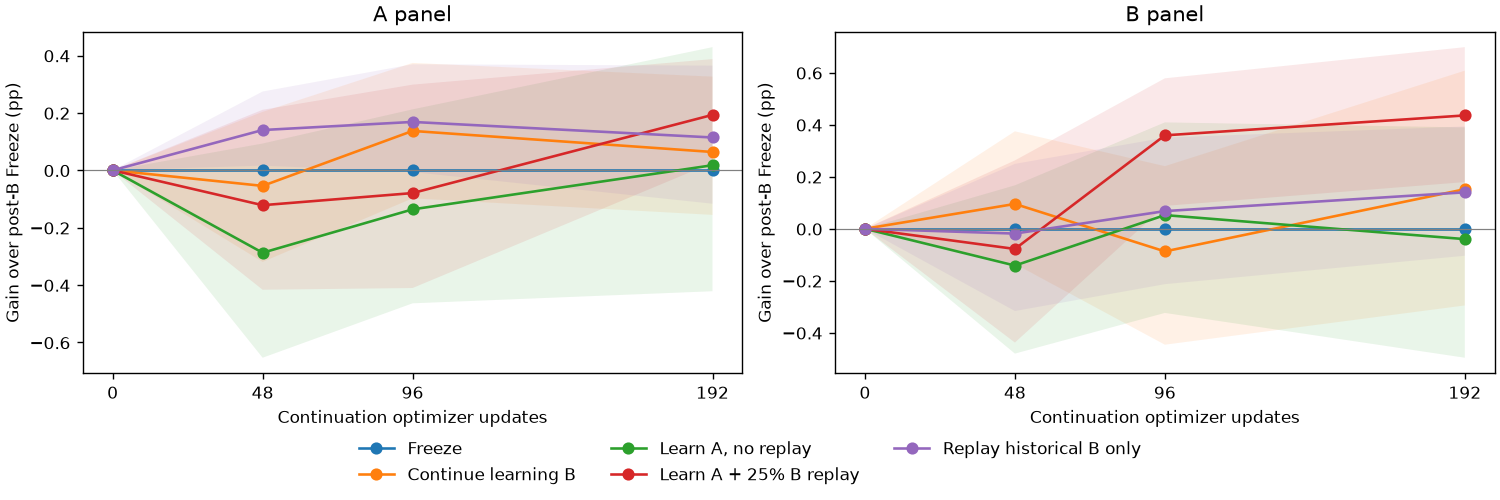